# Skin Lesion Classification with a CNN

Classifies dermatoscopic images into **7 types of skin lesion** using a convolutional neural network (CNN) in TensorFlow/Keras.

**Dataset:** [DermaMNIST](https://medmnist.com/), the HAM10000 dermatoscopy dataset (10,015 images) resized to 28×28 RGB, with official train / validation / test splits.

**Notebook outline**
1. Explore the data and its class imbalance
2. Show why *oversampling before splitting* gives a misleading score (data leakage)
3. Train the CNN the correct way: balance only the training set
4. Improve it with augmentation, batch normalisation and dropout
5. Evaluate on the untouched test set
6. Save the model for the Streamlit app

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import train_test_split
from tensorflow import keras

from sklearn.metrics import roc_auc_score
from src.skin_lesion import (CODES, MODEL_PATH, NAMES, STATS_PATH, build_improved_model, build_model,
                             class_weights, fit_stats, load_split, oversample, preprocess, save_stats)

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
SHOTS = Path("screenshots"); SHOTS.mkdir(exist_ok=True)
sns.set_style("whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Explore the data

In [2]:
x_train, y_train = load_split("train")
x_val, y_val = load_split("val")
x_test, y_test = load_split("test")
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:>5}: {len(y):5d} images")
print("Image shape:", x_train.shape[1:])

train:  7007 images
  val:  1003 images
 test:  2005 images
Image shape: (28, 28, 3)


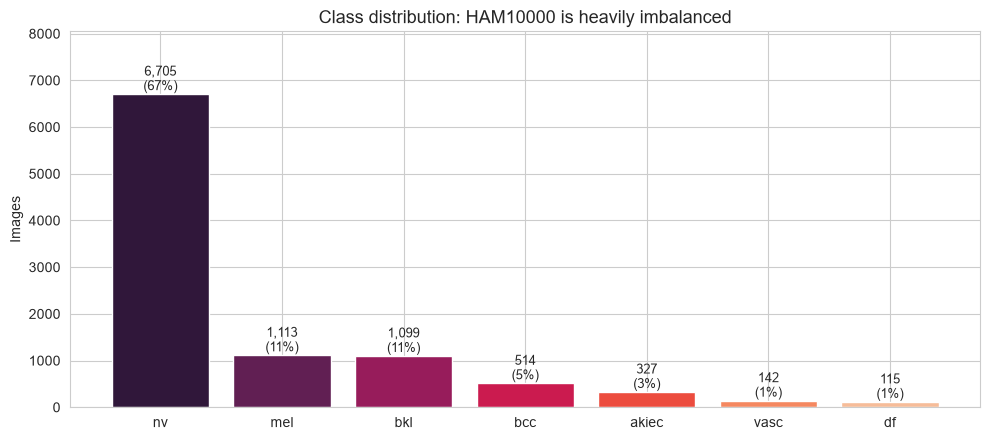

   nv  Melanocytic nevi                                  6705
  mel  Melanoma                                          1113
  bkl  Benign keratosis-like lesions                     1099
  bcc  Basal cell carcinoma                               514
akiec  Actinic keratoses / intraepithelial carcinoma      327
 vasc  Vascular lesions                                   142
   df  Dermatofibroma                                     115


In [3]:
y_all = np.concatenate([y_train, y_val, y_test])
counts = np.bincount(y_all)
order = np.argsort(counts)[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar([CODES[i] for i in order], counts[order], color=sns.color_palette("rocket", 7))
ax.bar_label(bars, labels=[f"{counts[i]:,}\n({counts[i] / counts.sum():.0%})" for i in order], fontsize=9)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Class distribution: HAM10000 is heavily imbalanced", fontsize=13)
ax.set_ylabel("Images")
plt.tight_layout(); plt.savefig(SHOTS / "class_distribution.png", dpi=110); plt.show()
for i in order:
    print(f"{CODES[i]:>5}  {NAMES[i]:<48} {counts[i]:5d}")

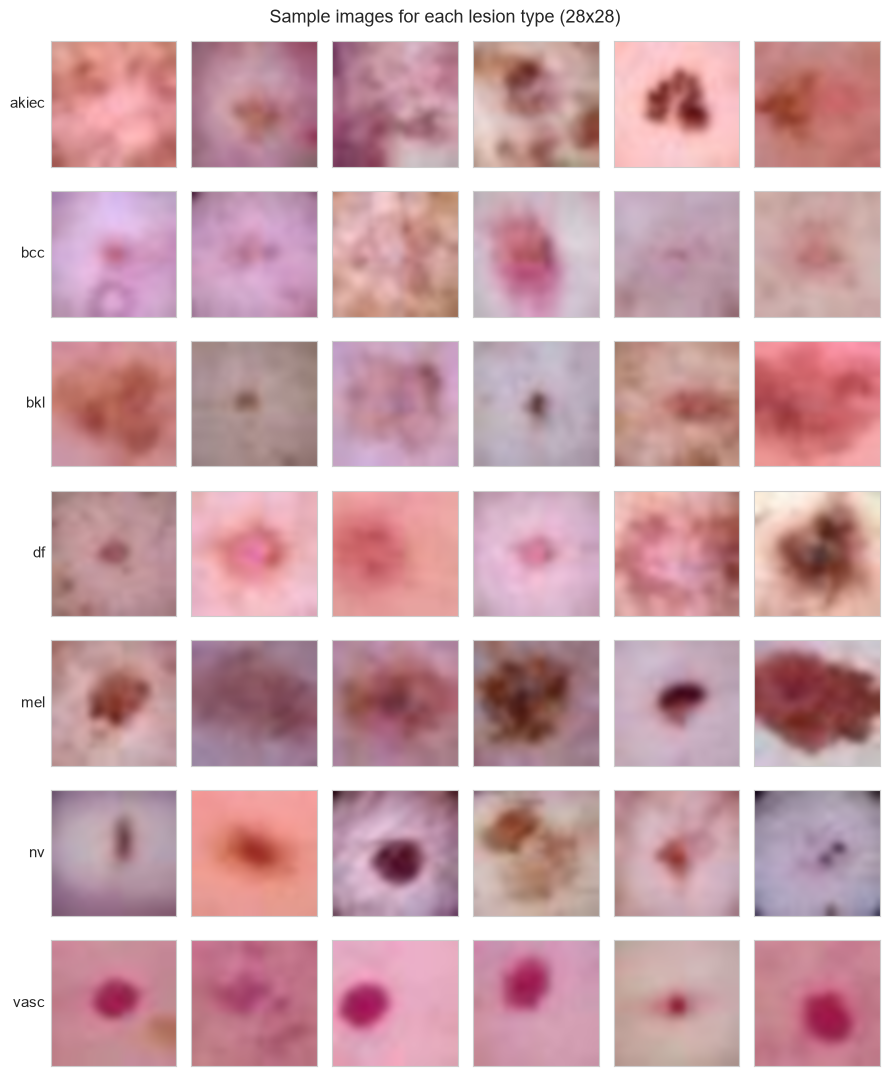

In [4]:
fig, axes = plt.subplots(7, 6, figsize=(9, 11))
for row, c in enumerate(range(7)):
    idx = np.random.default_rng(c).choice(np.where(y_train == c)[0], 6, replace=False)
    for col, i in enumerate(idx):
        ax = axes[row, col]
        ax.imshow(x_train[i], interpolation="bicubic"); ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(CODES[c], rotation=0, ha="right", va="center", fontsize=11)
fig.suptitle("Sample images for each lesion type (28x28)", fontsize=13)
plt.tight_layout(); plt.savefig(SHOTS / "sample_images.png", dpi=110); plt.show()

## 2. The data-leakage trap: oversampling *before* splitting

A common way to handle imbalance is random oversampling, which duplicates minority-class images until every class is the same size. If this is done **before** the train/test split, copies of the same image end up in both sets, so the model is tested on images it has already memorised.

Below, the same CNN is trained that way to show how inflated the score becomes.

In [5]:
x_all = np.concatenate([x_train, x_val, x_test])
x_os, y_os = oversample(x_all, y_all, seed=SEED)
xl_train, xl_test, yl_train, yl_test = train_test_split(x_os, y_os, test_size=0.2, random_state=1)
leak_stats = fit_stats(xl_train)

leaky = build_model()
leaky.fit(preprocess(xl_train, leak_stats), yl_train, validation_split=0.2, batch_size=128,
          epochs=12, verbose=0)
leaky_acc = leaky.evaluate(preprocess(xl_test, leak_stats), yl_test, verbose=0)[1]

# How many 'test' images are exact copies of training images?
train_keys = {img.tobytes() for img in xl_train}
overlap = np.mean([img.tobytes() in train_keys for img in xl_test])
print(f"Leaky test accuracy: {leaky_acc:.2%}")
print(f"Test images that also appear in the training set: {overlap:.1%}")

Leaky test accuracy: 95.28%
Test images that also appear in the training set: 85.9%


## 3. Train the CNN the correct way

- Use the official DermaMNIST splits, so **validation and test images are never seen in training**.
- Oversample **only the training set**.
- Standardise with the **training-set** mean and standard deviation, and save them so the app preprocesses images in exactly the same way.

In [6]:
x_bal, y_bal = oversample(x_train, y_train, seed=SEED)
stats = fit_stats(x_train)
X_bal, X_val, X_test = preprocess(x_bal, stats), preprocess(x_val, stats), preprocess(x_test, stats)
X_train = preprocess(x_train, stats)
print("Balanced training set:", X_bal.shape, np.bincount(y_bal))

model = build_model()
model.summary()

Balanced training set: (32851, 28, 28, 3) [4693 4693 4693 4693 4693 4693 4693]


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 182,663 (713.53 KB)

 Trainable params: 182,663 (713.53 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, mode="max",
                                           restore_best_weights=True)
history = model.fit(X_bal, y_bal, validation_data=(X_val, y_val), batch_size=128, epochs=30,
                    callbacks=[early_stop], verbose=2)

Epoch 1/30


257/257 - 42s - 163ms/step - accuracy: 0.5111 - loss: 1.2555 - val_accuracy: 0.5444 - val_loss: 1.1132


Epoch 2/30


257/257 - 37s - 142ms/step - accuracy: 0.7822 - loss: 0.6023 - val_accuracy: 0.5962 - val_loss: 1.0298


Epoch 3/30


...

257/257 - 38s - 148ms/step - accuracy: 0.9889 - loss: 0.0328 - val_accuracy: 0.6939 - val_loss: 2.0876


Epoch 13/30


257/257 - 38s - 149ms/step - accuracy: 0.9930 - loss: 0.0217 - val_accuracy: 0.7059 - val_loss: 2.2365


Epoch 14/30


257/257 - 38s - 146ms/step - accuracy: 0.9822 - loss: 0.0546 - val_accuracy: 0.7019 - val_loss: 2.1582


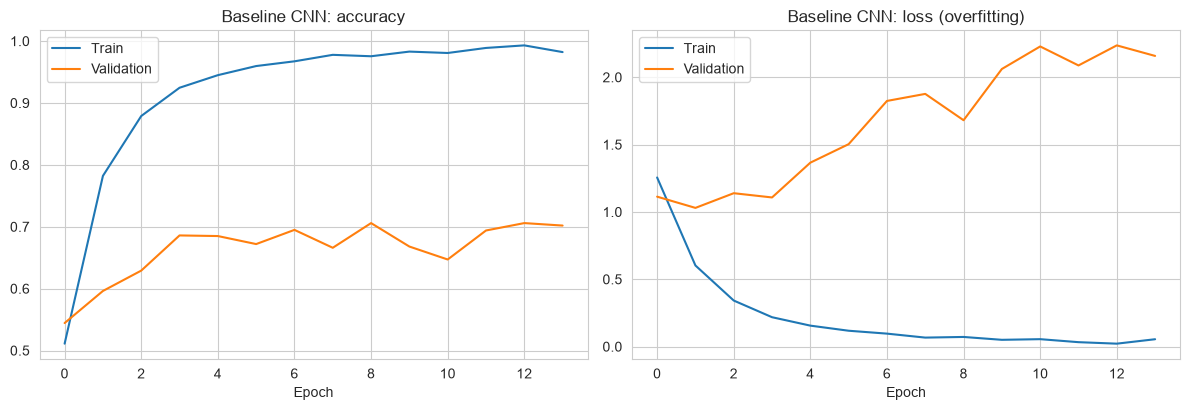

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(history.history["accuracy"], label="Train"); ax1.plot(history.history["val_accuracy"], label="Validation")
ax1.set_title("Baseline CNN: accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()
ax2.plot(history.history["loss"], label="Train"); ax2.plot(history.history["val_loss"], label="Validation")
ax2.set_title("Baseline CNN: loss (overfitting)"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(SHOTS / "baseline_training_curves.png", dpi=110); plt.show()

In [9]:
base_probs = model.predict(X_test, verbose=0)
base_pred = base_probs.argmax(axis=1)
base = {"accuracy": np.mean(base_pred == y_test), "balanced": balanced_accuracy_score(y_test, base_pred),
        "auc": roc_auc_score(y_test, base_probs, multi_class="ovr")}
print("Baseline CNN on test set:", {k: round(float(v), 4) for k, v in base.items()})

Baseline CNN on test set: {'accuracy': 0.6988, 'balanced': 0.4989, 'auc': 0.8553}


## 4. Improved CNN

The baseline overfits badly: about 99% training accuracy against roughly 70% on validation. The improved model adds:
- **Data augmentation** (random flips, rotations and zoom). Lesions have no natural orientation, so these are label-preserving.
- **Batch normalisation** and **dropout**.
- **Global average pooling** instead of a large flattened dense layer.
- **Softened class weights** instead of oversampling, so it trains on the 7,007 real images rather than 32,851 partly duplicated ones.

In [10]:
keras.utils.set_random_seed(SEED)
model = build_improved_model()
model.summary()
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=60, batch_size=64,
                    class_weight=class_weights(y_train), callbacks=callbacks, verbose=2)

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 28, 28, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 7, 7, 128)      │       147,45

 Total params: 305,767 (1.17 MB)

 Trainable params: 304,871 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

...

110/110 - 46s - 416ms/step - accuracy: 0.7468 - loss: 1.4357 - val_accuracy: 0.6969 - val_loss: 0.7332 - learning_rate: 3.1250e-05


Epoch 39/60


110/110 - 48s - 434ms/step - accuracy: 0.7453 - loss: 1.4271 - val_accuracy: 0.6909 - val_loss: 0.7373 - learning_rate: 1.5625e-05


Epoch 40/60


110/110 - 83s - 753ms/step - accuracy: 0.7487 - loss: 1.4382 - val_accuracy: 0.6959 - val_loss: 0.7294 - learning_rate: 1.5625e-05


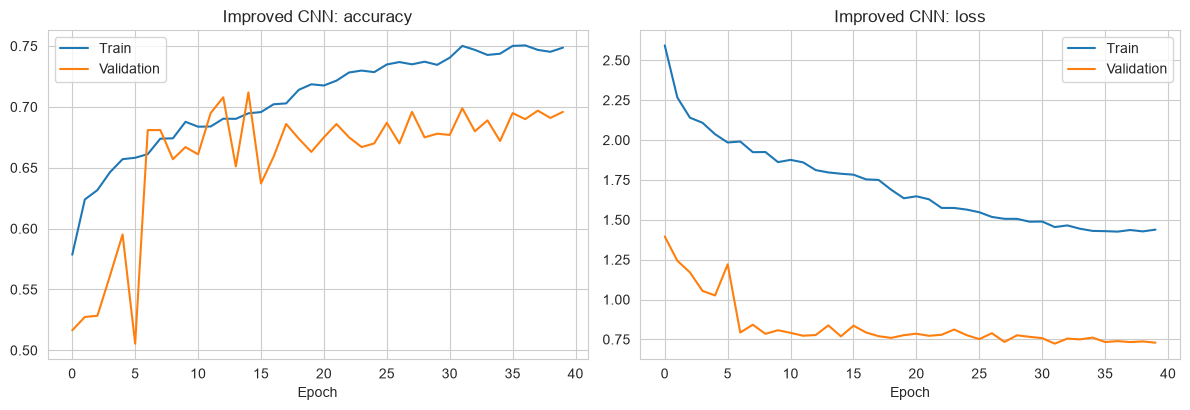

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(history.history["accuracy"], label="Train"); ax1.plot(history.history["val_accuracy"], label="Validation")
ax1.set_title("Improved CNN: accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()
ax2.plot(history.history["loss"], label="Train"); ax2.plot(history.history["val_loss"], label="Validation")
ax2.set_title("Improved CNN: loss"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(SHOTS / "training_curves.png", dpi=110); plt.show()

## 5. Evaluate on the untouched test set

In [12]:
probs = model.predict(X_test, verbose=0)
y_pred = probs.argmax(axis=1)
test_acc = np.mean(y_pred == y_test)
bal_acc = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
auc = roc_auc_score(y_test, probs, multi_class="ovr")
baseline = np.mean(y_test == 5)  # always predicting the majority class ('nv')

print(f"Test accuracy:            {test_acc:.2%}")
print(f"Balanced accuracy:        {bal_acc:.2%}")
print(f"Macro F1-score:           {macro_f1:.3f}")
print(f"Macro AUC (one-vs-rest):  {auc:.3f}")
print(f"Baseline CNN accuracy:    {base['accuracy']:.2%}  (balanced {base['balanced']:.2%}, AUC {base['auc']:.3f})")
print(f"Majority-class baseline:  {baseline:.2%}")
print(f"Leaky (incorrect) score:  {leaky_acc:.2%}")
print()
print(classification_report(y_test, y_pred, target_names=CODES, digits=3))

Test accuracy:            70.52%
Balanced accuracy:        56.67%
Macro F1-score:           0.516
Macro AUC (one-vs-rest):  0.925
Baseline CNN accuracy:    69.88%  (balanced 49.89%, AUC 0.855)
Majority-class baseline:  66.88%
Leaky (incorrect) score:  95.28%

              precision    recall  f1-score   support

       akiec      0.290     0.606     0.392        66
         bcc      0.464     0.563     0.509       103
         bkl      0.531     0.464     0.495       220
          df      0.286     0.174     0.216        23
         mel      0.374     0.619     0.466       223
          nv      0.928     0.783     0.849      1341
        vasc      0.629     0.759     0.688        29

    accuracy                          0.705      2005
   macro avg      0.500     0.567     0.516      2005
weighted avg      0.766     0.705     0.726      2005



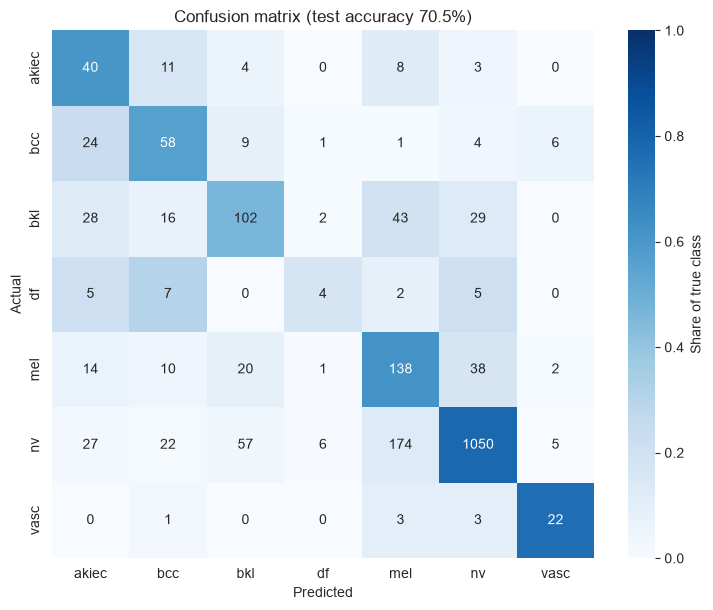

In [13]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(7.5, 6.2))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", xticklabels=CODES, yticklabels=CODES,
            cbar_kws={"label": "Share of true class"}, vmin=0, vmax=1)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion matrix (test accuracy {test_acc:.1%})")
plt.tight_layout(); plt.savefig(SHOTS / "confusion_matrix.png", dpi=110); plt.show()

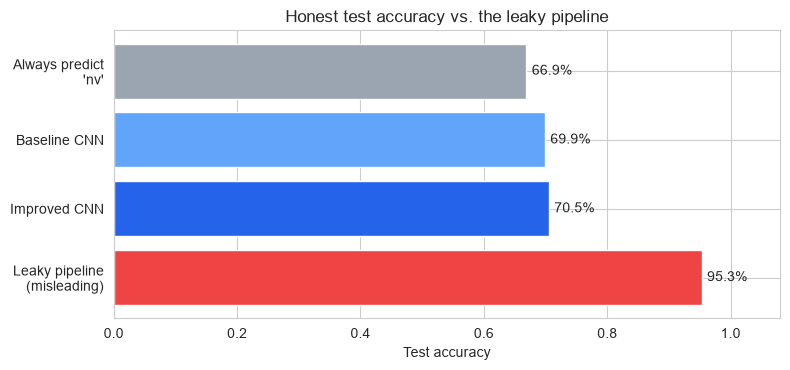

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = ["Always predict\n'nv'", "Baseline CNN", "Improved CNN", "Leaky pipeline\n(misleading)"]
values = [baseline, base["accuracy"], test_acc, leaky_acc]
colors = ["#9aa5b1", "#60a5fa", "#2563eb", "#ef4444"]
bars = ax.barh(labels, values, color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=4)
ax.set_xlim(0, 1.08); ax.invert_yaxis(); ax.set_xlabel("Test accuracy")
ax.set_title("Honest test accuracy vs. the leaky pipeline")
plt.tight_layout(); plt.savefig(SHOTS / "leakage_comparison.png", dpi=110); plt.show()

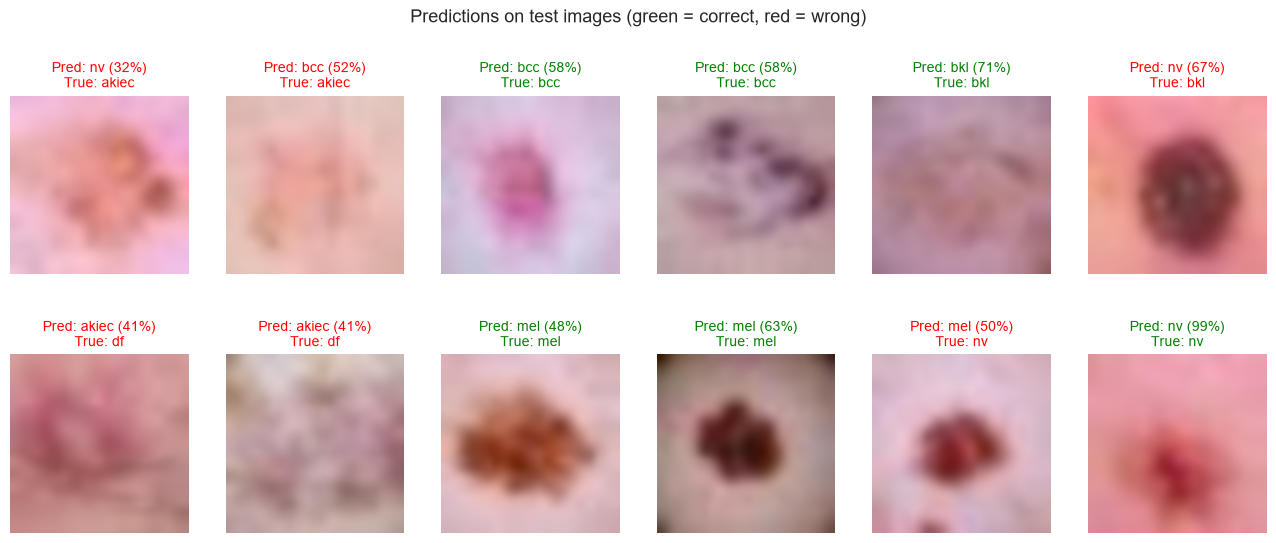

In [15]:
rng = np.random.default_rng(7)
idx = np.concatenate([rng.choice(np.where(y_test == c)[0], 2, replace=False) for c in range(7)])[:12]
fig, axes = plt.subplots(2, 6, figsize=(13, 5.4))
fig.subplots_adjust(left=0.01, right=0.99, top=0.82, bottom=0.01, wspace=0.1, hspace=0.45)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i], interpolation="bicubic"); ax.axis("off")
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"Pred: {CODES[y_pred[i]]} ({probs[i].max():.0%})\nTrue: {CODES[y_test[i]]}",
                 fontsize=10, color="green" if ok else "red")
fig.suptitle("Predictions on test images (green = correct, red = wrong)", fontsize=13)
plt.savefig(SHOTS / "sample_predictions.png", dpi=110, bbox_inches="tight"); plt.show()

## 6. Save the model and preprocessing statistics

In [16]:
MODEL_PATH.parent.mkdir(exist_ok=True)
model.save(MODEL_PATH)
save_stats(stats)
results = {"test_accuracy": round(float(test_acc), 4), "balanced_accuracy": round(float(bal_acc), 4),
           "macro_f1": round(float(macro_f1), 4), "macro_auc": round(float(auc), 4),
           "baseline_cnn_accuracy": round(float(base["accuracy"]), 4),
           "baseline_cnn_balanced_accuracy": round(float(base["balanced"]), 4),
           "baseline_cnn_auc": round(float(base["auc"]), 4), "majority_baseline": round(float(baseline), 4),
           "leaky_accuracy": round(float(leaky_acc), 4), "leaky_overlap": round(float(overlap), 4)}
Path("model/results.json").write_text(json.dumps(results, indent=2))
print("Saved", MODEL_PATH.name, "and", STATS_PATH.name)
print(results)

Saved skin_lesion_cnn.keras and preprocessing.json
{'test_accuracy': 0.7052, 'balanced_accuracy': 0.5667, 'macro_f1': 0.5165, 'macro_auc': 0.9249, 'baseline_cnn_accuracy': 0.6988, 'baseline_cnn_balanced_accuracy': 0.4989, 'baseline_cnn_auc': 0.8553, 'majority_baseline': 0.6688, 'leaky_accuracy': 0.9528, 'leaky_overlap': 0.8588}
